<a href="https://colab.research.google.com/github/augustoematos/python-data-analysis-portfolio/blob/main/brazilian_immigration_to_canada_1980_2013.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
plt.style.use('fivethirtyeight')
plt.style.use('tableau-colorblind10')

In [4]:
df = pd.read_csv('/content/canadian_immegration_data.csv')
df.set_index('Country', inplace=True)
years = list(map(str, range(1980, 2014)))

In [5]:
brazil = df.loc['Brazil', years]
brazil_dict = {'year': brazil.index.tolist(), 'immigrant': brazil.values.tolist()}
data_brazil = pd.DataFrame(brazil_dict)

In [6]:
argentina = df.loc['Argentina', years]
argentina_dict = {'year': argentina.index.tolist(), 'immigrant': argentina.values.tolist()}
data_argentina = pd.DataFrame(argentina_dict)

In [15]:
south_america = df.query('Region == "South America"')
south_america = south_america.sort_values('Total', ascending=True)

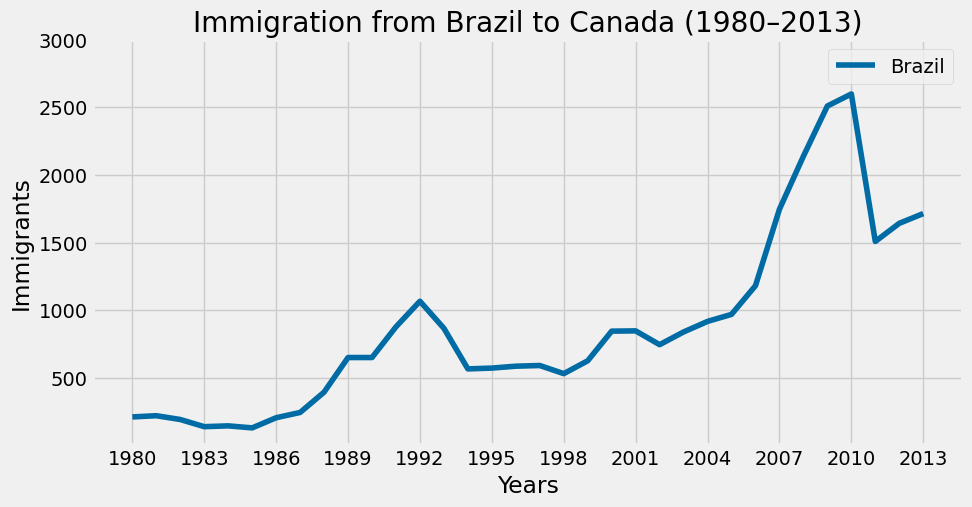

In [23]:
plt.figure(figsize=(10,5))
plt.plot(data_brazil['year'], data_brazil['immigrant'], label='Brazil')
plt.title('Immigration from Brazil to Canada (1980–2013)')
plt.xlabel('Years')
plt.ylabel('Immigrants')
plt.xticks(['1980', '1983', '1986', '1989', '1992', '1995', '1998', '2001', '2004', '2007', '2010', '2013'])
plt.yticks([500, 1000, 1500, 2000, 2500, 3000])
plt.legend()
plt.show()

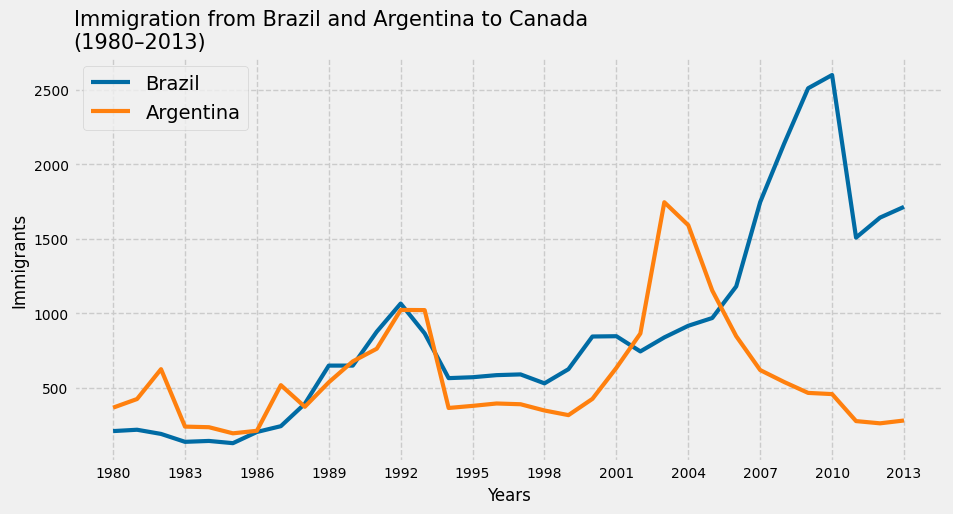

In [24]:
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(data_brazil['year'], data_brazil['immigrant'], label='Brazil', lw=3, marker='')
ax.plot(data_argentina['year'], data_argentina['immigrant'], label='Argentina', lw=3, marker='')
ax.set_title('Immigration from Brazil and Argentina to Canada \n(1980–2013)', fontsize=15, loc='left')
ax.set_xlabel('Years', fontsize=12)
ax.set_ylabel('Immigrants', fontsize=12)
ax.xaxis.set_tick_params(labelsize=10)
ax.yaxis.set_tick_params(labelsize=10)
ax.xaxis.set_major_locator(plt.MultipleLocator(3))
plt.legend()
plt.grid(linestyle='--')
plt.show()

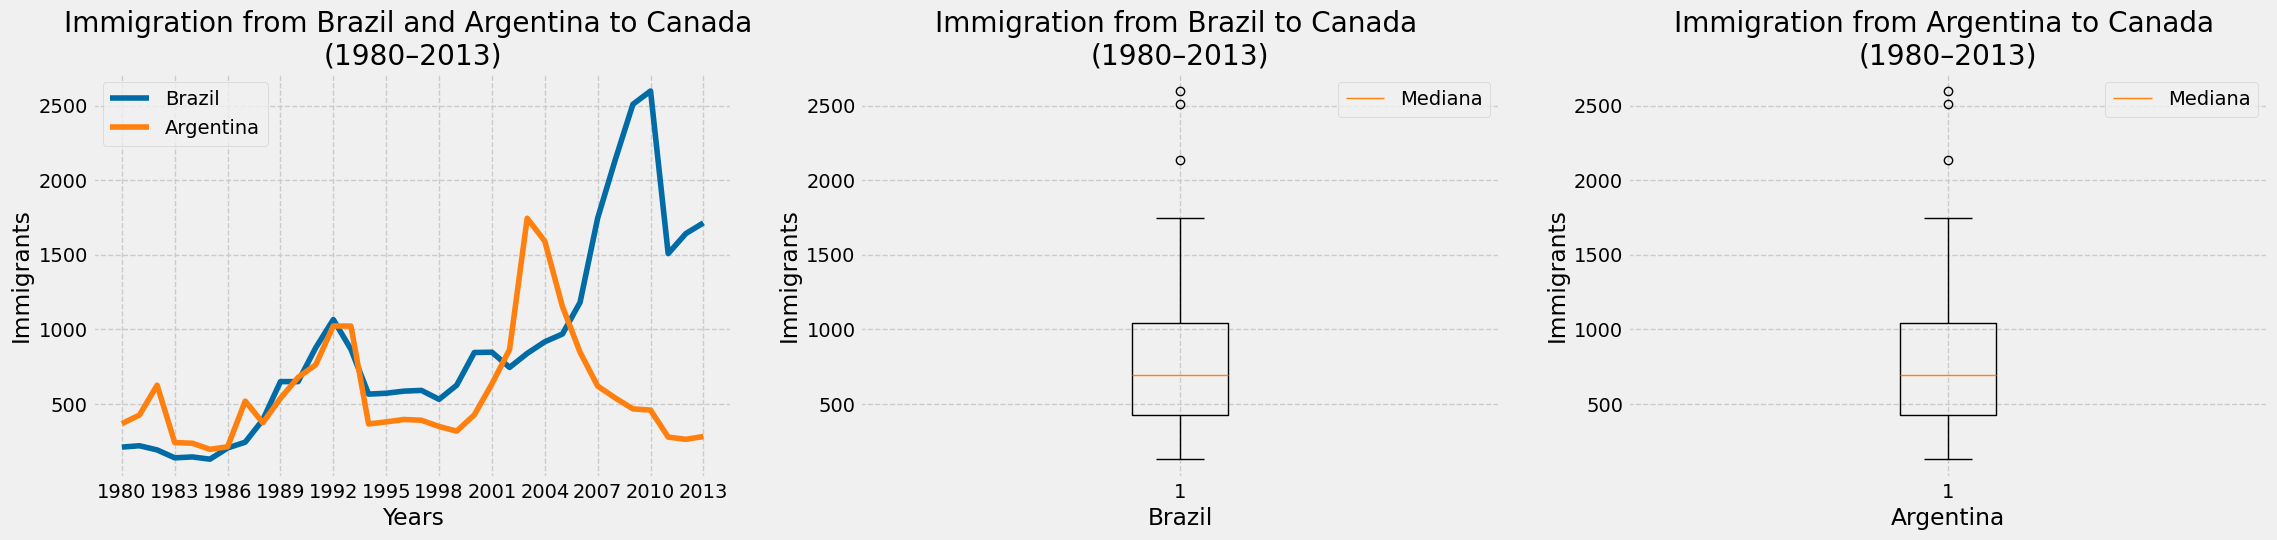

In [25]:
fig, axs = plt.subplots(1,3, figsize=(25,5))
axs[0].plot(data_brazil['year'], data_brazil['immigrant'], label='Brazil')
axs[0].plot(data_argentina['year'], data_argentina['immigrant'], label='Argentina')
axs[0].set_title('Immigration from Brazil and Argentina to Canada \n(1980–2013)')
axs[0].set_xlabel('Years')
axs[0].set_ylabel('Immigrants')
axs[0].xaxis.set_major_locator(plt.MultipleLocator(3))
axs[0].grid(linestyle='--')
axs[0].legend()

axs[1].boxplot(data_brazil['immigrant'], label='Mediana')
axs[1].set_title('Immigration from Brazil to Canada \n(1980–2013)')
axs[1].set_xlabel('Brazil')
axs[1].set_ylabel('Immigrants')
axs[1].grid(linestyle='--')
axs[1].legend()

axs[2].boxplot(data_brazil['immigrant'], label='Mediana')
axs[2].set_title('Immigration from Argentina to Canada \n(1980–2013)')
axs[2].set_xlabel('Argentina')
axs[2].set_ylabel('Immigrants')
axs[2].grid(linestyle='--')
axs[2].legend()

plt.show()

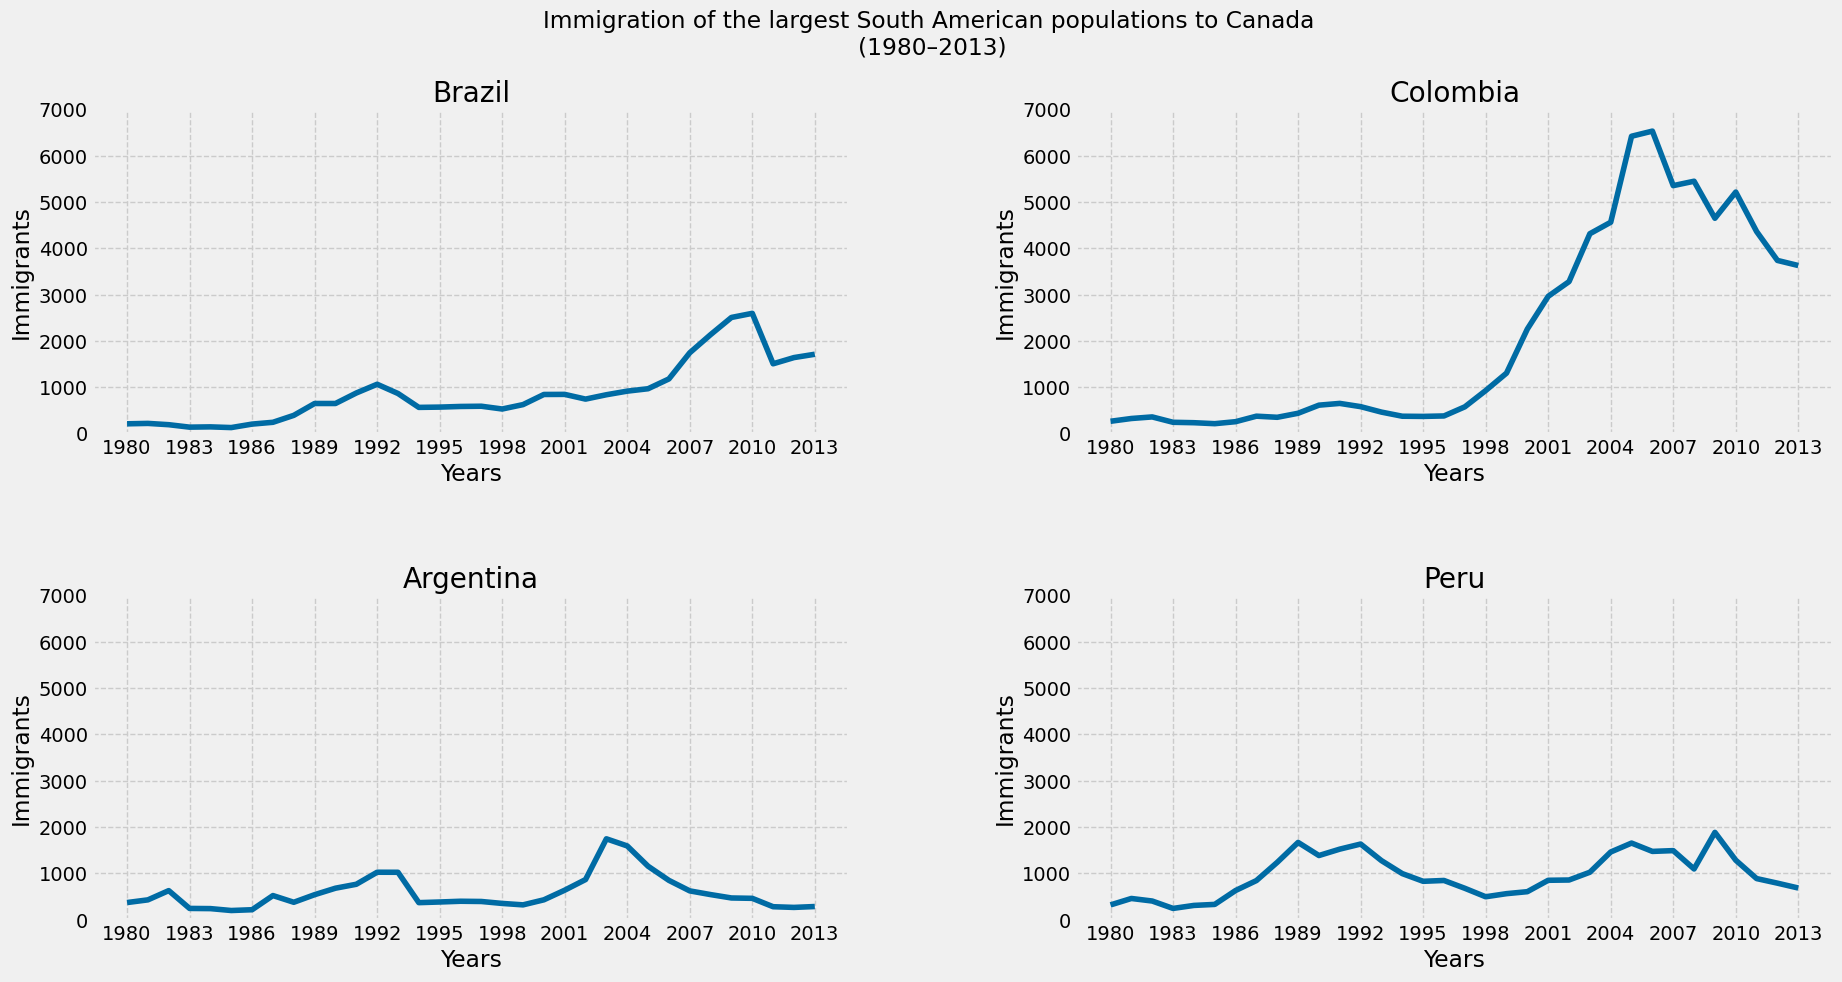

In [18]:
fig, axs = plt.subplots(2,2, figsize=(20,10))
fig.subplots_adjust(hspace=0.5, wspace=0.3)
fig.suptitle('Immigration of the largest South American populations to Canada \n(1980–2013)')
ymin = 0
ymax = 7000

axs[0,0].plot(df.loc['Brazil', years])
axs[0,0].set_title('Brazil')

axs[0,1].plot(df.loc['Colombia', years])
axs[0,1].set_title('Colombia')

axs[1,0].plot(df.loc['Argentina', years])
axs[1,0].set_title('Argentina')

axs[1,1].plot(df.loc['Peru', years])
axs[1,1].set_title('Peru')

for ax in axs.ravel():
  ax.set_ylim(ymin, ymax)

for ax in axs.flat:
  ax.xaxis.set_major_locator(plt.MultipleLocator(3))
  ax.set_xlabel('Years')
  ax.set_ylabel('Immigrants')
  ax.grid(linestyle='--')

plt.show()

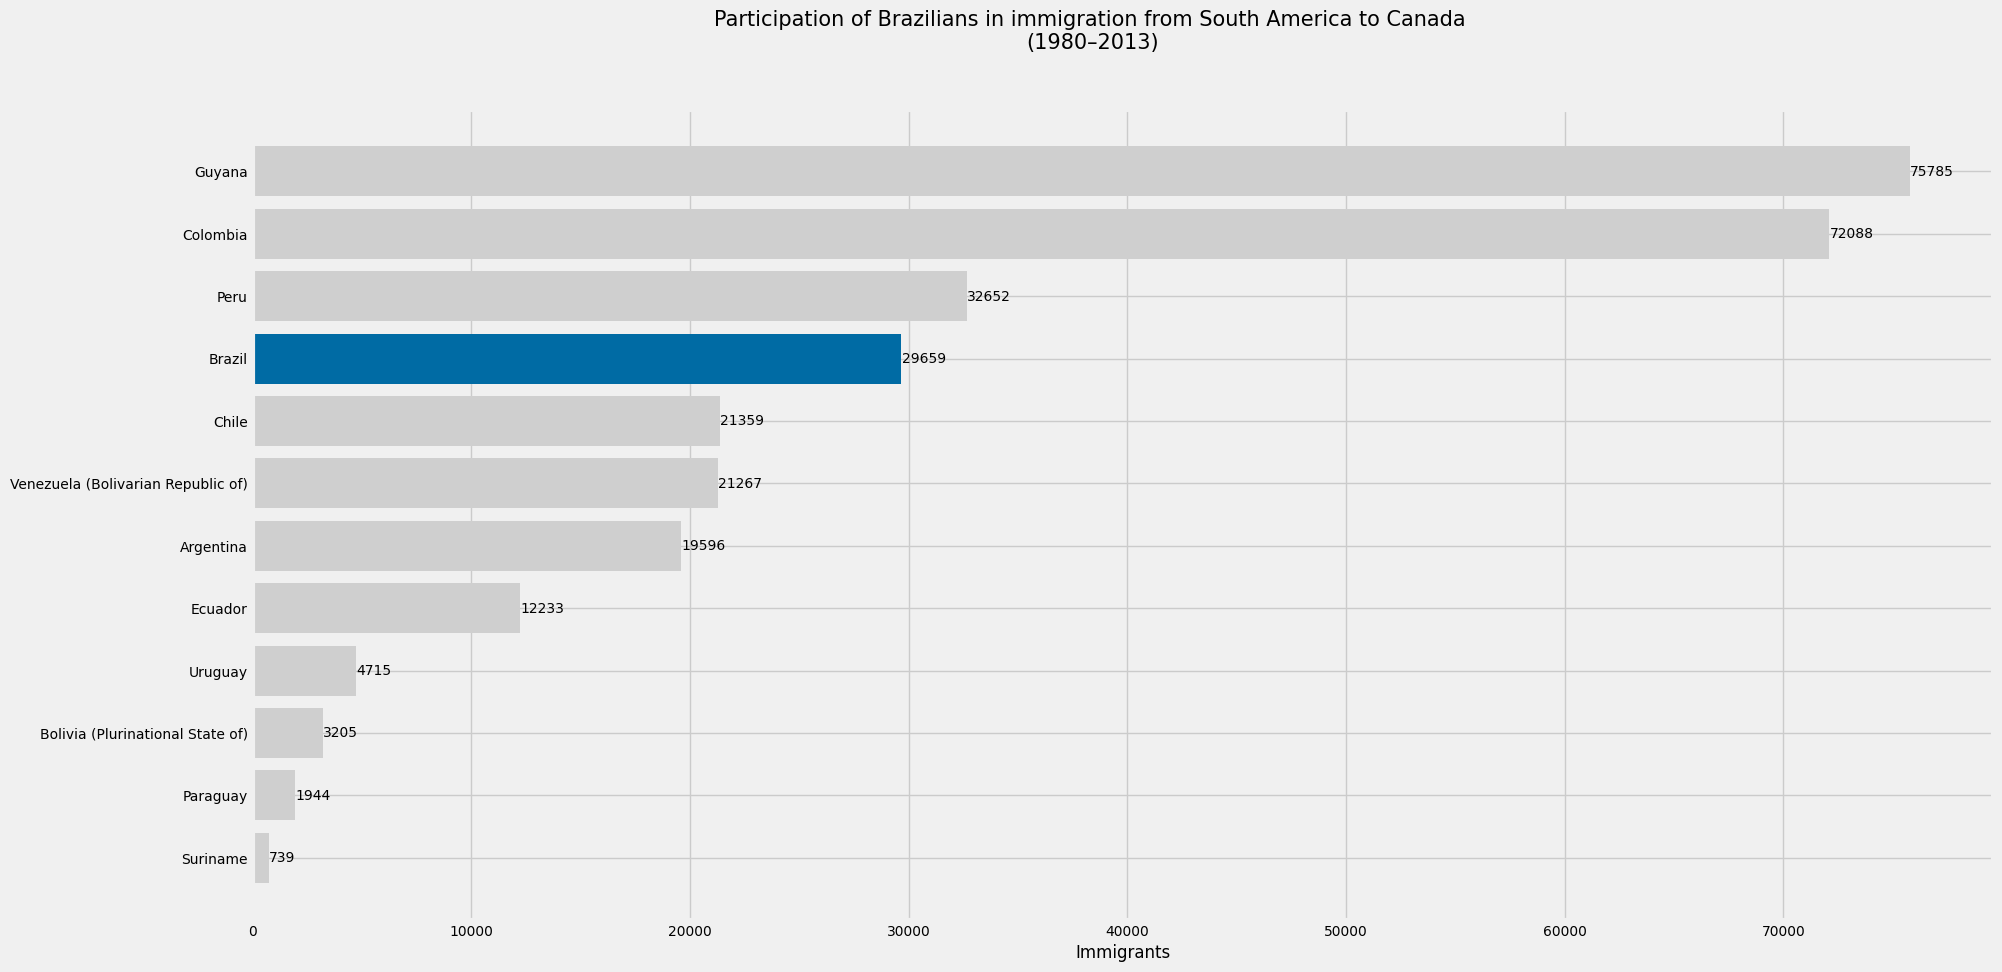

In [55]:
fig, ax = plt.subplots(figsize=(20,10))
fig.subplots_adjust(hspace=0.5, wspace=0.3)
fig.suptitle('Participation of Brazilians in immigration from South America to Canada \n(1980–2013)', fontsize=15)
ax.barh(south_america.index, south_america['Total'], color=colors)
ax.set_xlabel('Immigrants', fontsize=12)
ax.set_ylabel('')
ax.xaxis.set_tick_params(labelsize=10)
ax.yaxis.set_tick_params(labelsize=10)

colors = []
for country in south_america.index:
  if country == 'Brazil':
    colors.append('#006BA4')
  else:
    colors.append('#CFCFCF')

for i, v in enumerate(south_america['Total']):
  ax.text(v + 20, i, str(v), color='black', fontsize=10, ha='left', va='center')